In [241]:

import numpy as np
import matplotlib.pyplot as plt
import torch
from types import SimpleNamespace
import sys
import os
sys.path.append(os.path.abspath("./GLoRiPHY_source"))
from GLoRiPHY_source.demod import DemodImpl
from GLoRiPHY_source.mod import ModImpl

In [242]:
from GLoRiPHY_source.conformer_mod.model import *
from GLoRiPHY_source.utils import increase_dropout,spec_to_network_input, spec_to_network_input_complex, get_channel_estimate
def add_awgn(signal, snr_db):
    sig_power = np.mean(np.abs(signal) ** 2)
    snr_linear = 10 ** (snr_db / 10.0)
    noise_power = sig_power / snr_linear
    std_dev = np.sqrt(noise_power / 2.0)
    
    # Force the generated noise to be float32
    noise_real = np.random.randn(*signal.shape).astype(np.float32)
    noise_imag = np.random.randn(*signal.shape).astype(np.float32)
    noise = std_dev * (noise_real + 1j * noise_imag)
    
    return signal + noise

In [243]:
path_dataset = "Dataset/simulation/raw_sf8_custom_instance/ins1/1/85_7_35_8_125000_1.mat"
images_X = np.fromfile(path_dataset, dtype=np.complex64)

desired_snr = -21
# 2. Add the noise to images_X
noisy_images_X = add_awgn(images_X, desired_snr)
from types import SimpleNamespace
opts = SimpleNamespace(
    train_denoiseGenCore=True,
    sf=8,
    fs_bw_ratio=8,
    snr_list=None,                 # replace with actual list if available
    x_image_channel=2,
    normalization=1,

    transformer_encoder_dim=256,
    num_attention_heads=16,
    transformer_layers=2,
    attention_dropout=0.15,
    inp_dropout=0.1,
    ff_dropout=0.1,
    conv_dropout=0.1,

    lr=2e-4,
    beta1=0.5,
    beta2=0.999,
    sched_factor=0.4,
    sched_patience=7,

    mse_scaling=7700,

    num_epochs=700,
    load_epoch=-1,
    checkpoint_every=5,

    batch_size=1,
    train_data_size=1_000_000,
    test_data_size=5_000,

    phase1=200,
    phase2=400,
    phase3=600,

    early_stopping_patience=50,
    num_workers=13,

    root_path="GLoRiPHY_source",
    checkpoint_dir="GLoRiPHY_source/checkpointss/AWGN_Filter_new/simulation/SF",

    num_packets=50,
    num_perturbations=1000,

    test_choice="LoraPHY",
    test_nodes=None,

    stft_nfft=2048,
    stft_window=128,
    hop_length=64,
    freq_size=256,

    n_classes=256,

    num_perturbations_train=800,
    num_packets_train=42,
    dechirp = False,
    downchirp=None
    
)
opts.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
opts.hamming_window = torch.hamming_window(opts.stft_window).to(opts.device)
opts.demod = DemodImpl(opts.sf,fs_bw_ratio=opts.fs_bw_ratio,fft_factor=16)
opts.mod = ModImpl(opts.sf)
opts.downchirp = torch.tensor(opts.demod.d_downchirp[:opts.demod.d_num_samples]).unsqueeze(0).to(opts.device)
print(opts)

namespace(train_denoiseGenCore=True, sf=8, fs_bw_ratio=8, snr_list=None, x_image_channel=2, normalization=1, transformer_encoder_dim=256, num_attention_heads=16, transformer_layers=2, attention_dropout=0.15, inp_dropout=0.1, ff_dropout=0.1, conv_dropout=0.1, lr=0.0002, beta1=0.5, beta2=0.999, sched_factor=0.4, sched_patience=7, mse_scaling=7700, num_epochs=700, load_epoch=-1, checkpoint_every=5, batch_size=1, train_data_size=1000000, test_data_size=5000, phase1=200, phase2=400, phase3=600, early_stopping_patience=50, num_workers=13, root_path='GLoRiPHY_source', checkpoint_dir='GLoRiPHY_source/checkpointss/AWGN_Filter_new/simulation/SF', num_packets=50, num_perturbations=1000, test_choice='LoraPHY', test_nodes=None, stft_nfft=2048, stft_window=128, hop_length=64, freq_size=256, n_classes=256, num_perturbations_train=800, num_packets_train=42, dechirp=False, downchirp=tensor([[6.1232e-17-1.0000j, 3.8251e-01-0.9240j, 7.0656e-01-0.7076j,
          ..., 7.0656e-01-0.7076j, 3.8251e-01-0.9240

In [1]:
model = ConformerGen_Core(opts,
        conformer_for = f'sf_8',
        encoder_dim=opts.transformer_encoder_dim, 
        num_attention_heads= opts.num_attention_heads,
        num_encoder_layers=opts.transformer_layers,
        input_dropout_p = opts.inp_dropout,
        feed_forward_dropout_p = opts.ff_dropout,
        attention_dropout_p = opts.attention_dropout,
        conv_dropout_p = opts.conv_dropout)

NameError: name 'ConformerGen_Core' is not defined

In [245]:
conformer_path = "GLoRiPHY_source/checkpoints/AWGN_Filter_new/simulation/SF/best_conformer_jgj.pkl"
model.load_state_dict(torch.load( conformer_path, map_location=lambda storage, loc: storage),
        strict=True)

<All keys matched successfully>

In [246]:
images_X_tensor = torch.from_numpy(noisy_images_X).to(opts.device)
images_X_tensor = images_X_tensor.unsqueeze(0)
symbol_recd_stft = torch.stft(images_X_tensor, n_fft=opts.stft_nfft, hop_length=opts.hop_length, win_length=opts.stft_window, return_complex=True, pad_mode='constant',window=opts.hamming_window)
symbol_recd_stft = spec_to_network_input(symbol_recd_stft,opts)

print(symbol_recd_stft.shape)
with torch.no_grad():
    masked_symbol,outputs,preds = model(symbol_recd_stft)
    preds = torch.round(preds)
print(preds)
print(outputs.shape)
print(masked_symbol.shape)



torch.Size([1, 2, 256, 33])
tensor([249.])
torch.Size([1, 256])
torch.Size([1, 2, 256, 33])


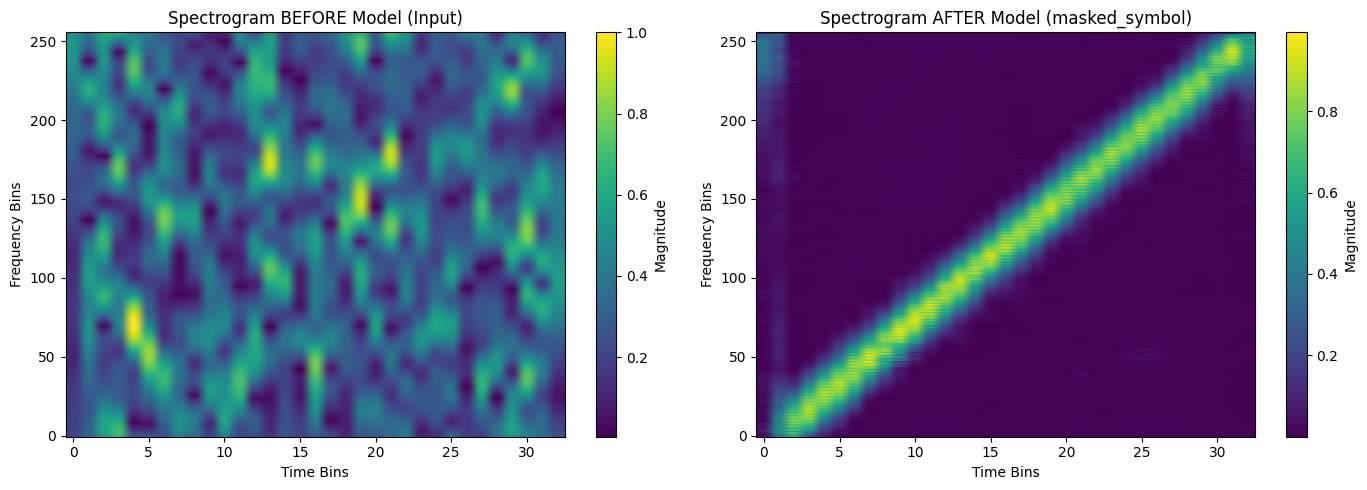

In [247]:
import matplotlib.pyplot as plt
import numpy as np
# 1. Extract the first sample in the batch (index 0)
# Shape is [2, H, W] where channel 0 is Real and channel 1 is Imaginary
input_spec = symbol_recd_stft[0].detach().cpu().numpy()
output_spec = masked_symbol[0].detach().cpu().numpy()
# 2. Compute the magnitude: sqrt(Real^2 + Imaginary^2)
input_magnitude = np.sqrt(input_spec[0]**2 + input_spec[1]**2)
output_magnitude = np.sqrt(output_spec[0]**2 + output_spec[1]**2)
# 3. Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Plot before model (Input)
im1 = axes[0].imshow(input_magnitude, aspect='auto', origin='lower', cmap='viridis')
axes[0].set_title("Spectrogram BEFORE Model (Input)")
axes[0].set_xlabel("Time Bins")
axes[0].set_ylabel("Frequency Bins")
fig.colorbar(im1, ax=axes[0], label="Magnitude")
# Plot after model (Output)
im2 = axes[1].imshow(output_magnitude, aspect='auto', origin='lower', cmap='viridis')
axes[1].set_title("Spectrogram AFTER Model (masked_symbol)")
axes[1].set_xlabel("Time Bins")
axes[1].set_ylabel("Frequency Bins")
fig.colorbar(im2, ax=axes[1], label="Magnitude")
plt.tight_layout()
plt.show()